# Running on IBM Quantum Hardware

**Course**: Quantum Computing Laboratory  
**Version**: 2.2 (Qiskit 2.2 Compatible)  
**Last Updated**: November 2025

---

## 📚 Overview

Learn how to access and execute quantum circuits on **real IBM Quantum hardware** using Qiskit 2.2's modern runtime services.

### Topics Covered:
- IBM Quantum account setup
- QiskitRuntimeService (new in Qiskit 2.0+)
- Backend selection strategies
- Job submission and monitoring
- Results analysis
- Best practices for hardware access

## 🎯 Learning Objectives

1. ✅ Set up IBM Quantum account
2. ✅ Configure QiskitRuntimeService
3. ✅ Select appropriate backends
4. ✅ Submit and monitor jobs
5. ✅ Analyze hardware results
6. ✅ Understand hardware limitations

## 🔧 Prerequisites

**Required:**
- IBM Quantum account (free at https://quantum.ibm.com)
- API token from IBM Quantum
- Qiskit 2.2+ installed
- qiskit-ibm-runtime package

**Installation:**
```bash
pip install qiskit==2.2.0 qiskit-ibm-runtime
```

## 🌐 Step 1: Get Your IBM Quantum Token

### How to Get Your Token:

1. **Create Account** (if you don't have one):
   - Go to https://quantum.ibm.com
   - Click "Sign up" or "Log in"
   - Complete registration (free)

2. **Find Your Token**:
   - Log in to IBM Quantum
   - Click your profile icon (top right)
   - Select "Account settings"
   - Find your API token
   - Click "Copy token"

3. **Important**: Keep your token **secret**! Never share it or commit it to Git.

### Free Tier Access (2025):
- **10 minutes/month** of quantum computing time
- Access to multiple quantum processors
- Simulator access (unlimited)
- Open quantum systems
- Queue priority: Standard

In [1]:
# Import QiskitRuntimeService (Qiskit 2.2)
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2   # the account/connection object and the Sampler primitive that runs circuits on IBM devices
from qiskit import QuantumCircuit                                 # the object we build circuits with
from qiskit.visualization import plot_histogram                   # bar chart of measurement counts
import warnings
warnings.filterwarnings('ignore')                                 # hide DeprecationWarnings of the fast-moving runtime package
from IPython.display import display                      # show a figure (e.g. a circuit drawing) from the middle of a cell
def draw(qc, fold=-1, **kw): return qc.draw("mpl", style="clifford", fold=fold, **kw)   # every circuit picture: matplotlib drawer; fold=-1 = one long row, fold=N wraps after N columns

print("✓ Imports successful!")
print("  QiskitRuntimeService ready (Qiskit 2.2)")


✓ Imports successful!
  QiskitRuntimeService ready (Qiskit 2.2)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2` | the package that talks to IBM Quantum: `QiskitRuntimeService` holds the account and lists the devices, `SamplerV2` sends circuits and returns bitstring counts |
| `warnings.filterwarnings('ignore')` | the runtime API changes every few months and prints DeprecationWarnings: hidden here, not an error |
| `draw(qc)` | our one-line helper around `qc.draw("mpl", style="clifford", fold=...)`; `display()` shows a figure that is not the last line of the cell |

</details>


## 💾 Step 2: Save Your Account (One-Time Setup)

### Save Credentials Securely

In [2]:
# FIRST TIME ONLY: Save your IBM Quantum account
# Replace 'YOUR_TOKEN_HERE' with your actual token

# Option 1: Save with token directly (for first time)
# QiskitRuntimeService.save_account(
#     channel="ibm_quantum_platform",   # the current channel name (the old "ibm_quantum" channel was retired in 2025)
#     token="YOUR_TOKEN_HERE",          # Paste your token here
#     set_as_default=True,              # this account is used when QiskitRuntimeService() is called with no arguments
#     overwrite=True                    # Use this to update token
# )
# The call writes ~/.qiskit/qiskit-ibm.json on this computer: it is NOT needed again in later sessions.

print("Account Setup Instructions:")
print("="*60)
print("1. Uncomment the code above")
print("2. Replace 'YOUR_TOKEN_HERE' with your actual token")
print("3. Run this cell once")
print("4. Comment it out again (for security)")
print("="*60)
print("\n⚠️  SECURITY: Never commit your token to Git!")
print("    Add this notebook to .gitignore if it contains your token")


Account Setup Instructions:
1. Uncomment the code above
2. Replace 'YOUR_TOKEN_HERE' with your actual token
3. Run this cell once
4. Comment it out again (for security)

⚠️  SECURITY: Never commit your token to Git!
    Add this notebook to .gitignore if it contains your token


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `QiskitRuntimeService.save_account(channel=..., token=..., set_as_default=True, overwrite=True)` | a one-time call (here commented out, so the cell is inert) that stores the token in `~/.qiskit/qiskit-ibm.json`; afterwards `QiskitRuntimeService()` finds it by itself |
| `channel="ibm_quantum_platform"` | the IBM Cloud channel used since mid-2025; the old `"ibm_quantum"` value of the original cell no longer works |
| `overwrite=True` | replace a previously saved token (e.g. after regenerating it on the website) |

</details>


### Better Approach: Use Environment Variable

In [3]:
# Recommended: Use environment variable for token
import os                                      # os.getenv / os.environ: read the variables of the shell that launched Jupyter

# In your terminal, set: export IBM_QUANTUM_TOKEN="your_token_here"
# Or in Python:
# os.environ['IBM_QUANTUM_TOKEN'] = 'your_token_here'

# Then save:
# token = os.getenv('IBM_QUANTUM_TOKEN')       # None if the variable is not set
# if token:
#     QiskitRuntimeService.save_account(
#         channel="ibm_quantum_platform",
#         token=token,
#         set_as_default=True,
#         overwrite=True
#     )
#     print("✓ Account saved successfully!")
# else:
#     print("✗ IBM_QUANTUM_TOKEN environment variable not set")

print("Using environment variables is more secure!")


Using environment variables is more secure!


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `os.getenv('IBM_QUANTUM_TOKEN')` | reads a shell variable: the token lives in the shell's memory, never in the notebook file (which may end up on GitHub) |
| `if token: ... else: ...` | `None` and the empty string are *falsy* in Python: the save is skipped with a message if the variable is missing |
| the whole cell is commented | nothing runs here either: it prints one line; uncomment to use it |

</details>


## 🔌 Step 3: Load Your Account

In [4]:
# Load saved credentials (after setup)
try:
    service = QiskitRuntimeService()           # no arguments: load the default account saved on this computer
    print("✓ IBM Quantum service loaded successfully!")
    print(f"  Connected as: {service.channel}")   # 'ibm_quantum_platform'
except Exception as e:                         # no saved account, bad token, no network ...: any failure lands here
    print(f"✗ Error loading service: {e}")
    print("\nTroubleshooting:")
    print("  1. Make sure you've run the save_account() step above")
    print("  2. Check your token is correct")
    print("  3. Verify internet connection")
    service = None                             # the flag every hardware cell below tests: `if service:` -> skip with a message


✗ Error loading service: "Unable to find account. Please make sure an account with the channel name 'ibm_quantum_platform' is saved."

Troubleshooting:
  1. Make sure you've run the save_account() step above
  2. Check your token is correct
  3. Verify internet connection


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `try: ... except Exception as e:` | the guard that keeps the notebook usable without an account: the exception becomes a printed message and `service = None` |
| `QiskitRuntimeService()` | with no arguments it reads `~/.qiskit/qiskit-ibm.json`; without a saved account it raises `AccountNotFoundError` — the message you see when running this notebook offline |
| `service.channel` | which API the account talks to (`ibm_quantum_platform`); the original cell used the private attribute `service._account.channel` |
| `service = None` | downstream cells test `if service:` / `if backend:` / `if job:` and print a message instead of raising |

</details>


## 🖥️ Step 4: Explore Available Backends

In [5]:
# List all available backends
if service:                                    # only with a loaded account
    backends = service.backends()              # every device your instance can use (a list of backend objects)
    
    print(f"Available backends: {len(backends)}")
    print("="*70)
    
    for backend in backends:
        config = backend.configuration()       # static description: number of qubits, basis gates, limits
        status = backend.status()              # live description: operational flag, queue length
        
        # Backend info
        name = backend.name
        n_qubits = config.n_qubits
        operational = "✓" if status.operational else "✗"    # conditional expression (ternary)
        pending = status.pending_jobs          # jobs queued in front of yours
        simulator = "(Simulator)" if config.simulator else "(Hardware)"
        
        print(f"{operational} {name:20s} {n_qubits:2d} qubits  Queue: {pending:4d}  {simulator}")   # :20s / :2d / :4d = fixed-width columns
    
    print("="*70)
else:
    print("Service not loaded. Please complete account setup first.")


Service not loaded. Please complete account setup first.


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `service.backends()` | the devices visible to your account; on the free plan a handful of 127/156-qubit machines (no cloud simulators any more) |
| `backend.configuration()` vs `backend.status()` | static data (qubits, gates, limits) vs live data (operational, `pending_jobs` = queue length) |
| `f"{name:20s} {n_qubits:2d}"` | format specifiers inside an f-string: pad the name to 20 characters, the integer to 2 — aligned columns |
| `else:` branch | without an account the cell prints one line and does nothing else |

</details>


## 🎯 Step 5: Smart Backend Selection

In [6]:
# Select least busy backend
if service:
    # Method 1: Least busy hardware backend
    backend = service.least_busy(              # the device with the shortest queue among those matching the filters
        operational=True,                      # skip machines under maintenance
        simulator=False,                       # real hardware only
        min_num_qubits=5                       # enough qubits for our 2-qubit circuit (and a bit more)
    )
    
    print("Selected Backend:")
    print("="*60)
    print(f"  Name: {backend.name}")
    print(f"  Qubits: {backend.configuration().n_qubits}")
    print(f"  Queue: {backend.status().pending_jobs} jobs")
    print(f"  Operational: {backend.status().operational}")
    print("="*60)
    
    # Get backend properties
    config = backend.configuration()
    print(f"\nBackend Details:")
    print(f"  Max circuits: {config.max_experiments}")           # how many circuits one job may contain
    print(f"  Max shots: {config.max_shots}")                    # repetitions per circuit
    print(f"  Basis gates: {', '.join(config.basis_gates[:5])}...")   # the native gate set (e.g. ecr, id, rz, sx, x); [:5] = the first five
else:
    backend = None                             # the flag read by the transpilation / submission cells
    print("No service available")


No service available


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `service.least_busy(operational=True, simulator=False, min_num_qubits=5)` | one call that applies three filters and returns the device with the fewest pending jobs: the usual choice for a short experiment |
| `config.basis_gates` | the native gates of the chip (on IBM Heron/Eagle: `ecr`/`cz`, `rz`, `sx`, `x`, plus `measure`); the transpiler must rewrite our H and CNOT in these |
| `config.max_shots` | typically 100 000: the hard limit on repetitions per circuit in one job |
| `backend = None` | offline the cell prints `No service available` and the rest of the notebook keeps testing this flag |

</details>


### Alternative: Select Specific Backend

In [7]:
# Method 2: Select by name
if service:
    # backend = service.backend('ibm_brisbane')  # Specific backend
    # backend = service.backend('ibm_sherbrooke')  # Another option
    
    # Method 3: Filter by criteria
    filtered_backends = service.backends(
        filters=lambda x: x.configuration().n_qubits >= 5 and     # lambda: an anonymous one-line function, called on every backend x
                         not x.configuration().simulator and
                         x.status().operational                   # keep x only if all three conditions hold
    )
    
    print(f"Backends with ≥5 qubits (operational): {len(filtered_backends)}")
    for b in filtered_backends[:5]:  # Show first 5
        print(f"  - {b.name}: {b.configuration().n_qubits} qubits")
else:
    print("No service available: `service.backend('ibm_brisbane')` and the filter need an account")


No service available: `service.backend('ibm_brisbane')` and the filter need an account


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `service.backend('ibm_brisbane')` | a device by name: what you use when you want to repeat an experiment on the same chip (names change as machines are retired) |
| `filters=lambda x: ...` | `service.backends` calls your function on every device and keeps those returning True: an arbitrary selection rule |
| `filtered_backends[:5]` | list slicing: at most the first five entries |

</details>


## 🔨 Step 6: Create a Test Circuit

Test Circuit (Bell State):
  Qubits: 2
  Depth: 3
  Gates: 4


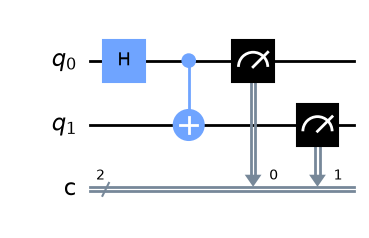

↑ the Bell-pair test circuit: H, CNOT, two measurements — ideally only '00' and '11' come out, half of the shots each


In [8]:
# Create a simple Bell state circuit
qc = QuantumCircuit(2, 2)         # QuantumCircuit(number_of_qubits, number_of_classical_bits)
qc.h(0)                           # Hadamard on qubit 0 -> (|0> + |1>)/sqrt2
qc.cx(0, 1)                       # CNOT, control 0, target 1 -> entangled Bell pair (|00> + |11>)/sqrt2
qc.measure([0, 1], [0, 1])        # measure(qubits, classical_bits): qubit i -> bit i

print("Test Circuit (Bell State):")
print(f"  Qubits: {qc.num_qubits}")
print(f"  Depth: {qc.depth()}")   # layers of gates that cannot run in parallel: H, CNOT, measurements = 3
print(f"  Gates: {qc.size()}")    # every instruction counts, measurements included: 4

display(draw(qc)); print("↑ the Bell-pair test circuit: H, CNOT, two measurements — ideally only '00' and '11' come out, half of the shots each")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qc.h(0)`, `qc.cx(0, 1)` | the Bell pair (\|00⟩ + \|11⟩)/√2: superposition, then entanglement — the smallest circuit whose two outcomes are perfectly correlated |
| `qc.depth()`, `qc.size()` | 3 layers, 4 instructions: the numbers the transpiler will change (more gates, same physics) |
| `display(draw(qc))` | the picture of the circuit as written: no device yet, so no native gates and no physical qubits |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**What 1024 shots of a Bell pair should look like.**

Ideal device: $|\psi\rangle = (|00\rangle + |11\rangle)/\sqrt2$, so $P(00) = P(11) = 1/2$ and $P(01) = P(10) = 0$. The number of `00` outcomes in $N = 1024$ shots is binomial with mean $N/2 = 512$ and standard deviation $\sqrt{N \cdot \tfrac12 \cdot \tfrac12} = 16$: anything between about 480 and 544 is a perfectly normal ideal histogram (the Aer cell in Step 11 gives such numbers).

Real device: each measurement has a readout error $\epsilon_r \approx 1\text{–}3\,\%$ and the CNOT an error $\epsilon_{2q} \approx 0.5\text{–}1\,\%$, so a few per cent of the shots land on the *forbidden* outcomes `01` and `10`:

$$P(01) + P(10) \approx 2\epsilon_r + \epsilon_{2q} \approx 3\text{–}5\,\% \quad(\approx 30\text{–}50 \text{ shots of } 1024).$$

The Hellinger fidelity of Step 11, $F = \left(\sum_x \sqrt{p_x q_x}\right)^2$, is then $\approx (2\sqrt{0.5 \cdot 0.48})^2 \approx 0.96$: just above the 0.95 threshold, the “Excellent agreement!” branch. The reference solution of the In-depth section finds exactly this on the fake 5-qubit backend `FakeManilaV2`.

</details>


## 🚀 Step 7: Transpile for Hardware

In [9]:
# Transpile circuit for selected backend
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager   # the transpiler, configured for one backend

if backend:
    print("Transpiling for hardware...")
    
    # Create pass manager with high optimization
    pm = generate_preset_pass_manager(
        optimization_level=3,  # Maximum optimization (0-3): more passes, fewer gates, slower compilation
        backend=backend        # native gates + connectivity + calibration of this device
    )
    
    # Transpile
    transpiled_qc = pm.run(qc)                 # the ISA circuit: only native gates, on physical qubits
    
    print("\nTranspilation Results:")
    print("="*60)
    print(f"  Original depth: {qc.depth()}")
    print(f"  Transpiled depth: {transpiled_qc.depth()}")
    print(f"  Original gates: {qc.size()}")
    print(f"  Transpiled gates: {transpiled_qc.size()}")
    print(f"  2-qubit gates: {transpiled_qc.num_nonlocal_gates()}")   # the noisy ones: one CNOT -> one ecr/cz (plus 1-qubit rotations)
    print("="*60)
    
    print(f"\nCircuit optimized for: {backend.name}")
    display(draw(transpiled_qc, idle_wires=False)); print(f"↑ the ISA circuit: H became rz/sx rotations, CNOT became one native two-qubit gate — {dict(transpiled_qc.count_ops())} (idle_wires=False hides the ~125 unused physical qubits)")
else:
    print("Backend not available for transpilation")
    transpiled_qc = qc                         # offline fallback: the untranspiled circuit, so that later cells still have something to count


Backend not available for transpilation


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `generate_preset_pass_manager(optimization_level=3, backend=backend)` | the standard Qiskit 2 transpiler: a pipeline of passes (layout, routing, basis translation, optimization) built for this device |
| `pm.run(qc)` | the ISA circuit (*instruction set architecture*): only the device's native gates, on chosen physical qubits — the only thing a hardware Sampler accepts |
| `num_nonlocal_gates()` | the count of two-qubit gates: each costs ~10× the error of a one-qubit gate, so this is the number to minimise |
| `transpiled_qc = qc` | the offline fallback printed with `Backend not available for transpilation`: the time estimate of the Best Practices section still runs |

</details>


## 📤 Step 8: Submit Job to Hardware

In [10]:
# Submit job using SamplerV2
from qiskit_ibm_runtime import SamplerV2 as IBMSampler   # the hardware Sampler (same class as SamplerV2 imported above, just an alias)
import time

if backend:
    print(f"Submitting job to {backend.name}...")
    print("="*60)
    
    # Create sampler
    # non funziona   # sampler = IBMSampler(backend=backend)
    sampler = SamplerV2(backend)               # SamplerV2(mode=backend): the primitive bound to one device ('job' mode)

    # Submit job
    job = sampler.run([transpiled_qc], shots=1024)   # a list of circuits (one 'pub' each); returns at once, the job runs in the cloud
    
    print(f"✓ Job submitted!")
    print(f"  Job ID: {job.job_id()}")         # the handle to fetch the result later, even from another session
    print(f"  Save this ID to retrieve results later!")
    print("="*60)
    
    # Store job ID for later retrieval
    job_id = job.job_id()
else:
    print("Backend not available")
    job = None                                 # the flag read by the monitoring / results cells


Backend not available


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `SamplerV2(backend)` | the Sampler primitive in job mode: every `run` is one job in the device queue (a `Session` would keep the device reserved between jobs) |
| `sampler.run([transpiled_qc], shots=1024)` | asynchronous: the call returns a job object immediately; the circuit must already be an ISA circuit |
| `job.job_id()` | a string like `d1abc...`: with it `service.job(id)` retrieves the result days later |
| `job = None` | offline: `Backend not available` and nothing is submitted |

</details>


## ⏱️ Step 9: Monitor Job Progress

In [11]:
# Monitor job with timeout
if job:
    print("Monitoring job progress...")
    print("="*60)
    
    start_time = time.time()
    max_wait = 3600  # 1 hour timeout
    check_interval = 30  # Check every 30 seconds
    
    def job_status(job):
        """Status as a plain string: runtime >= 0.40 returns 'DONE', older versions an enum with .name."""
        status = job.status()
        return getattr(status, "name", status)   # getattr(obj, attr, default): the enum's .name if it has one, else the string itself
    
    while job_status(job) not in ['DONE', 'ERROR', 'CANCELLED']:   # loop until a final state
        elapsed = int(time.time() - start_time)
        
        if elapsed > max_wait:
            print("\n⚠️  Timeout exceeded (1 hour)")
            print("  Job is still running - retrieve later with job ID")
            break
        
        # Get status
        status = job_status(job)               # 'QUEUED', 'RUNNING', ...
        #queue_pos = job.queue_position()      # not available on RuntimeJobV2
        
        # Display progress
        print(f"[{elapsed:4d}s] Status: {status:15s}", end="")
        #if queue_pos:
        #    print(f" | Queue position: {queue_pos}")
        #else:
        #    print(" | Running...")
        #
        if status in ['DONE', 'ERROR', 'CANCELLED']:
            break
        
        time.sleep(check_interval)             # wait before asking the server again (polling)
    
    print("="*60)
    print(f"Final status: {job_status(job)}")
    print(f"Total time: {int(time.time() - start_time)}s")
else:
    print("No job to monitor (no backend / no account)")


No job to monitor (no backend / no account)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `job.status()` | asks the server; in qiskit-ibm-runtime ≥ 0.40 it returns a plain string (`'QUEUED'`, `'RUNNING'`, `'DONE'`, …), in older versions an enum — `job_status()` accepts both via `getattr(status, 'name', status)` |
| `while ... not in [...]` | polling: ask, print, sleep 30 s, repeat until a final state; `break` leaves the loop on timeout |
| `time.time()` | seconds since 1970 as a float: differences give elapsed wall-clock time |
| `else:` branch | offline (`job is None`) the cell prints one line — the original cell was silent, but the next one raised |

</details>


In [12]:
if job:
    print(job.metrics())                       # a dict from the server: timestamps, quantum seconds used ('usage'), number of executions
else:
    print("No job: job.metrics() needs a submitted job (it returns timestamps and the quantum seconds used)")


No job: job.metrics() needs a submitted job (it returns timestamps and the quantum seconds used)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `job.metrics()` | server-side bookkeeping: `timestamps` (created / running / finished), `usage` = the quantum seconds charged to your monthly quota |
| `if job:` guard | the original one-liner raised `AttributeError: 'NoneType' object has no attribute 'metrics'` without an account; now it prints a message |

</details>


### Retrieve Job Later

In [13]:
# Retrieve a job by ID (useful if you closed notebook)
if service:
    # Replace with your job ID
    # retrieved_job = service.job('YOUR_JOB_ID_HERE')
    # print(f"Retrieved job status: {retrieved_job.status()}")
    
    print("To retrieve a job later:")
    print("  job = service.job('your_job_id_here')")
    print("  result = job.result()")
else:
    print("No service: `service.job('your_job_id_here')` needs a loaded account")


No service: `service.job('your_job_id_here')` needs a loaded account


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `service.job('id')` | rebuilds the job object from its id: results stay on IBM's servers for weeks, so you can close the notebook while the job queues |
| `job.result()` | blocks until the job is done, then returns the result (the same object as in the next cell) |

</details>


## 📊 Step 10: Get and Analyze Results

In [14]:
# Get results
if job:
    status = job.status(); status = getattr(status, "name", status)   # plain string in runtime >= 0.40, enum (.name) before
else:
    status = None
if job and status == 'DONE':
    print("Retrieving results...")
    
    result = job.result()                      # a PrimitiveResult: one entry per circuit (pub) submitted
    counts = result[0].data.c.get_counts()     # .data.<classical register name>: our QuantumCircuit(2, 2) names it 'c'
    
    print("\n✓ Results obtained!")
    print("="*60)
    print("Measurement outcomes:")
    for state, count in sorted(counts.items(), key=lambda x: -x[1]):   # most frequent first
        prob = count / sum(counts.values())
        print(f"  |{state}⟩: {count:4d} ({prob:.3f})")
    print("="*60)
    
    # Plot
    display(plot_histogram(counts, title=f'Results from {backend.name}'))   # display(): the figure is inside an if-block, not the last line
else:
    print("Job not complete or not available")
    counts = None                              # the flag read by the comparison cell


Job not complete or not available


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `getattr(status, "name", status)` | the fix of the original `job.status().name`: the string `'DONE'` has no `.name`, the old enum had one — this works with both |
| `result[0].data.c.get_counts()` | SamplerV2 results are indexed by pub (circuit) and then by classical register *name*: `c` for `QuantumCircuit(2, 2)` (the original `.meas` is the name `measure_all()` gives) |
| `sorted(counts.items(), key=lambda x: -x[1])` | the outcomes ordered by decreasing count; `x[1]` is the count of the pair (bitstring, count) |
| `counts = None` | offline: `Job not complete or not available`; the next cell still runs the ideal simulation |

</details>


## 🔬 Step 11: Compare with Ideal Simulation

Ideal simulation (1024 shots): {'11': 527, '00': 497}

No hardware counts to compare (run Steps 8-10 with an account); the ideal histogram alone:


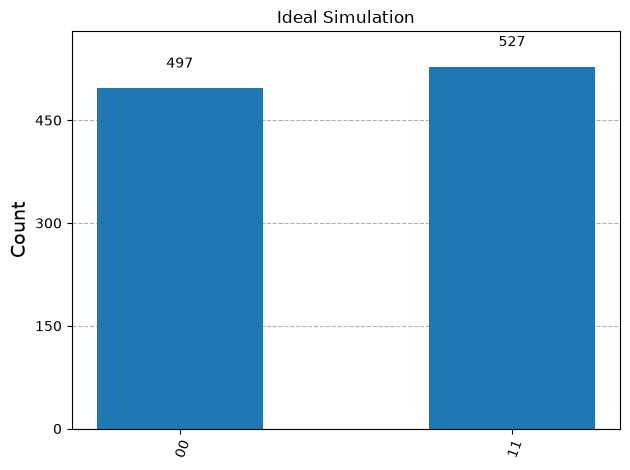

↑ the noise-free Bell pair: two bars of ~512 shots, the reference every device is measured against


In [15]:
# Compare hardware results with ideal simulation
from qiskit_aer import AerSimulator                     # local classical simulator of a quantum computer
from qiskit_aer.primitives import SamplerV2 as AerSampler   # the same SamplerV2 interface, backed by Aer
from qiskit.quantum_info import hellinger_fidelity      # overlap of two count dictionaries: 1 = identical distributions
import matplotlib.pyplot as plt

# Run ideal simulation (always: it is the reference, and it needs no account)
simulator = AerSimulator()                              # noise-free
sim_sampler = AerSampler()
pm_sim = generate_preset_pass_manager(optimization_level=1, backend=simulator)
sim_qc = pm_sim.run(qc)

sim_job = sim_sampler.run([sim_qc], shots=1024)
sim_result = sim_job.result()
sim_counts = sim_result[0].data.c.get_counts()          # register 'c' (see the previous cell)
print(f"Ideal simulation (1024 shots): {sim_counts}")   # only '00' and '11', about 512 each

if counts:                                              # hardware counts exist only after a real run
    # Calculate fidelity
    fidelity = hellinger_fidelity(counts, sim_counts)
    
    print(f"\nSimulation vs Hardware Comparison")
    print("="*60)
    print(f"Hellinger Fidelity: {fidelity:.4f}")
    
    if fidelity > 0.95:
        print("✓ Excellent agreement!")
    elif fidelity > 0.85:
        print("✓ Good agreement (typical for NISQ devices)")
    elif fidelity > 0.70:
        print("⚠️  Moderate agreement (noticeable noise)")
    else:
        print("⚠️  Significant noise effects")
    print("="*60)
    
    # Plot comparison
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))   # two histograms side by side
    plot_histogram(sim_counts, ax=ax1, title='Ideal Simulation')
    plot_histogram(counts, ax=ax2, title=f'Hardware ({backend.name})')
    plt.tight_layout()
    plt.show()
else:
    print("\nNo hardware counts to compare (run Steps 8-10 with an account); the ideal histogram alone:")
    display(plot_histogram(sim_counts, title='Ideal Simulation')); print("↑ the noise-free Bell pair: two bars of ~512 shots, the reference every device is measured against")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `AerSimulator()` + `AerSampler()` | the local noise-free reference: the same `run([circuit], shots=...)` / `result()[0].data.c.get_counts()` calls as on hardware |
| ideal run outside the `if` | the original cell did everything inside `if counts:` and showed nothing offline; the simulation is now always computed and the comparison only when hardware counts exist |
| `hellinger_fidelity(counts, sim_counts)` | $F = (\sum_x \sqrt{p_x q_x})^2$ between the two normalised histograms: 1 for identical distributions, ≈ 0.96 for a Bell pair with 4 % wrong outcomes |
| `plt.subplots(1, 2)` | one figure, two axes; `ax=` tells `plot_histogram` where to draw |

</details>


## 💡 Best Practices

### 1. Always Simulate First

In [16]:
print("Hardware Execution Workflow:")
print("="*60)
print("1. ✓ Develop circuit in simulation")
print("2. ✓ Verify circuit logic works correctly")
print("3. ✓ Optimize circuit depth and gate count")
print("4. ✓ Test transpilation for target backend")
print("5. ✓ Submit to hardware")
print("6. ✓ Compare results with simulation")
print("="*60)
print("\nWhy simulate first?")
print("  • Hardware time is limited (free tier: 10 min/month)")
print("  • Queue times can be long")
print("  • Debugging is much faster in simulation")
print("  • Validate circuit before using quantum time")


Hardware Execution Workflow:
1. ✓ Develop circuit in simulation
2. ✓ Verify circuit logic works correctly
3. ✓ Optimize circuit depth and gate count
4. ✓ Test transpilation for target backend
5. ✓ Submit to hardware
6. ✓ Compare results with simulation

Why simulate first?
  • Hardware time is limited (free tier: 10 min/month)
  • Queue times can be long
  • Debugging is much faster in simulation
  • Validate circuit before using quantum time


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `print(...)` only | a checklist, no computation: steps 1–4 are free (Aer, `generate_preset_pass_manager` with a fake backend), 5–6 cost quantum seconds |
| `"="*60` | string repetition: a 60-character rule |

</details>


### 2. Manage Your Quantum Time

In [17]:
# Estimate quantum time usage
def estimate_quantum_time(circuit, shots=1024, gate_time_ns=100):
    """
    Estimate quantum execution time.
    
    Args:
        circuit: QuantumCircuit
        shots: Number of circuit repetitions
        gate_time_ns: Average gate time in nanoseconds
    
    Returns:
        Estimated time in seconds
    """
    # Circuit execution time per shot
    circuit_time = circuit.size() * gate_time_ns * 1e-9   # size() = number of instructions; 1e-9 converts ns -> s
    
    # Total quantum time
    total_time = circuit_time * shots                     # every shot re-runs the whole circuit
    
    return total_time

# Example
est_time = estimate_quantum_time(transpiled_qc)           # offline transpiled_qc is the 4-instruction circuit itself
print(f"Estimated quantum time: {est_time*1000:.2f} ms")  # 4 x 100 ns x 1024 = 0.41 ms
print(f"With queue/overhead: ~{est_time*10:.2f}s - {est_time*60:.2f}s")
print(f"\nFree tier budget: 600 seconds/month")
print(f"This job uses: ~{est_time:.4f}s ({est_time/600*100:.2f}% of monthly quota)")


Estimated quantum time: 0.41 ms
With queue/overhead: ~0.00s - 0.02s

Free tier budget: 600 seconds/month
This job uses: ~0.0004s (0.00% of monthly quota)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `circuit.size() * gate_time_ns * 1e-9` | a crude per-shot time: every instruction counted as 100 ns (real 1-qubit gates take ~30 ns, two-qubit gates ~70–300 ns, a measurement ~1 µs) |
| `total_time = circuit_time * shots` | shots are sequential: the quantum time scales linearly with them |
| `est_time*1000:.2f` | seconds → milliseconds with two decimals; offline the 4-instruction circuit gives 0.41 ms |
| `est_time/600*100` | the share of the 600 quantum seconds of the free monthly quota: a Bell pair is negligible, a 1000-gate circuit × 10 000 shots is 1 s ≈ 0.2 % |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The author's time estimate, by hand.** The formula of `estimate_quantum_time` is

$$T \;=\; N_{\rm gates}\times t_{\rm gate}\times N_{\rm shots}.$$

Offline `transpiled_qc` is the untranspiled Bell circuit, $N_{\rm gates} = 4$ (H, CNOT, two measurements), $t_{\rm gate} = 100\ \text{ns}$, $N_{\rm shots} = 1024$:

$$T = 4 \times 10^{-7}\,\text{s}\times 1024 = 4.096\times 10^{-4}\ \text{s} = 0.41\ \text{ms},$$

i.e. $0.41/600\,000 \approx 7\times 10^{-5}\,\%$ of the monthly quota — the cell prints `0.41 ms` and `0.00%`. On a real device the ISA circuit has about 7 instructions (rz, sx, the two-qubit gate, measurements), so $T \approx 0.7$ ms. The server's own accounting (`job.metrics()['usage']`) is larger — a few seconds — because each shot also includes the qubit reset (~100 µs on IBM devices) and the measurement readout (~1 µs), which dominate over the ~100 ns of gates.

</details>


### 3. Error Handling

In [18]:
# Robust job submission
def submit_job_safely(sampler, circuit, shots=1024):
    """
    Submit job with error handling.
    """
    try:
        job = sampler.run([circuit], shots=shots)   # may raise: network down, circuit not ISA, quota exhausted ...
        print(f"✓ Job submitted: {job.job_id()}")
        return job
    except Exception as e:
        print(f"✗ Error submitting job: {e}")
        return None                                 # the caller tests `if job is None`

print("Error handling best practices:")
print("  • Always wrap submissions in try-except")
print("  • Save job IDs immediately")
print("  • Implement timeouts for monitoring")
print("  • Handle network interruptions gracefully")


Error handling best practices:
  • Always wrap submissions in try-except
  • Save job IDs immediately
  • Implement timeouts for monitoring
  • Handle network interruptions gracefully


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `def submit_job_safely(sampler, circuit, shots=1024)` | a wrapper that turns any submission error into a printed message and `None` — the pattern used by the `if job:` guards of this notebook |
| `except Exception as e` | catches every error type; `e` carries the server's message (invalid token, circuit not transpiled, quota exceeded) |
| only a definition | nothing is submitted here: `submit_job_safely(sampler, transpiled_qc)` would be the call with a loaded account |

</details>


## 🔬 In-depth analysis

Everything above that needs an account can be rehearsed **offline** with a *fake backend*: `qiskit_ibm_runtime.fake_provider` ships snapshots (gate set, coupling map, calibration data) of real IBM devices, and `AerSimulator.from_backend(fake)` builds a noisy simulator from them.

1. **A device on your laptop.** Create `FakeManilaV2` (a 5-qubit snapshot). Print its name, number of qubits, native gates (`fake.operation_names`) and coupling map (`fake.coupling_map.get_edges()`). Transpile the Bell circuit `qc` for it with `generate_preset_pass_manager(optimization_level=3, backend=fake)`, draw the result and report `count_ops()`, `depth()` and the number of two-qubit gates — this is Step 7 without an account.
2. **A noisy run.** Run the transpiled circuit on `AerSimulator.from_backend(fake)` with 1024 shots and compare with the ideal `AerSimulator()`: print both count dictionaries, the fraction of *forbidden* outcomes (`01` + `10`) and the Hellinger fidelity. Which branch of the Step 11 verdict (`> 0.95`, `> 0.85`, …) does the fake device land in?
3. **Depth vs fidelity.** Insert $k$ extra pairs of CNOTs (a CNOT squared is the identity, so the ideal outcome is unchanged) between the CNOT and the measurements, for $k = 0, 2, 4, 8, 16$. For each $k$ print the transpiled depth, the fidelity on the fake device and the author's `estimate_quantum_time` for 1024 shots. How fast does the fidelity decay with the number of two-qubit gates?

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [19]:
# 🔬 In-depth analysis — your code here



(1) fake_manila: 5 qubits, native gates ['cx', 'delay', 'for_loop', 'id', 'if_else', 'measure', 'reset', 'rz', 'switch_case', 'sx', 'x']
    coupling map: 8 directed edges [(0, 1), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2), (3, 4), (4, 3)] -> a line 0-1-2-3-4
    transpiled: {'rz': 2, 'measure': 2, 'sx': 1, 'cx': 1}, depth 5, 1 two-qubit gate(s) (original: depth 3, 4 instructions)


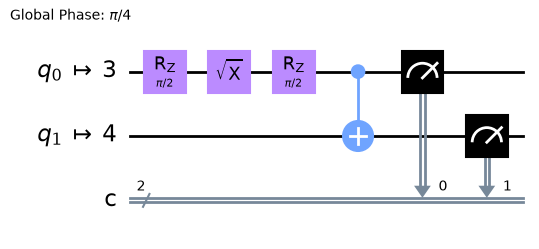

↑ the Bell pair in Manila's native gates: H = rz·sx·rz (level 3 drops the rotations that do nothing), CNOT = cx on a connected pair; the physical qubits are labelled on the left


(2) ideal {'00': 518, '11': 506}
    noisy {'01': 19, '11': 516, '10': 25, '00': 464}
    forbidden outcomes 01 + 10: 4.3% of the shots; Hellinger fidelity 0.956 -> excellent
(3)  k  extra cx  depth  fidelity  est. quantum time
     0         0      5     0.946    0.61 ms   (1 cx in the ISA circuit)


     2         4      9     0.928    1.02 ms   (5 cx in the ISA circuit)
     4         8     13     0.908    1.43 ms   (9 cx in the ISA circuit)


     8        16     21     0.877    2.25 ms   (17 cx in the ISA circuit)
    16        32     37     0.823    3.89 ms   (33 cx in the ISA circuit)


In [20]:
# Reference solution
from qiskit_ibm_runtime.fake_provider import FakeManilaV2   # a snapshot of the 5-qubit ibmq_manila: gates, coupling map, calibration

# (1) the fake device and the Bell circuit transpiled for it
fake = FakeManilaV2()
edges = list(fake.coupling_map.get_edges())                 # directed pairs (control, target) that can host a CNOT
print(f"(1) {fake.name}: {fake.num_qubits} qubits, native gates {sorted(fake.operation_names)}")
print(f"    coupling map: {len(edges)} directed edges {edges} -> a line 0-1-2-3-4")
pm_fake = generate_preset_pass_manager(optimization_level=3, backend=fake)
qc_fake = pm_fake.run(qc)                                   # the ISA circuit for Manila: rz, sx, x, cx on physical qubits
print(f"    transpiled: {dict(qc_fake.count_ops())}, depth {qc_fake.depth()}, "
      f"{qc_fake.num_nonlocal_gates()} two-qubit gate(s) (original: depth {qc.depth()}, {qc.size()} instructions)")
display(draw(qc_fake, idle_wires=False)); print("↑ the Bell pair in Manila's native gates: H = rz·sx·rz (level 3 drops the rotations that do nothing), CNOT = cx on a connected pair; the physical qubits are labelled on the left")

# (2) a noisy run vs the ideal one
noisy_sim = AerSimulator.from_backend(fake)                 # Aer with the noise model (gate errors, readout errors, T1/T2) of the snapshot
noisy_counts = noisy_sim.run(qc_fake, shots=1024).result().get_counts()
ideal_counts = AerSimulator().run(qc_fake, shots=1024).result().get_counts()
IDEAL = {'00': 0.5, '11': 0.5}                              # the exact Bell distribution: a reference without shot noise of its own
wrong = (noisy_counts.get('01', 0) + noisy_counts.get('10', 0)) / 1024   # the outcomes a perfect Bell pair never gives
fid = hellinger_fidelity(noisy_counts, IDEAL)
verdict = "excellent" if fid > 0.95 else "good (typical NISQ)" if fid > 0.85 else "moderate" if fid > 0.70 else "significant noise"
print(f"(2) ideal {ideal_counts}\n    noisy {noisy_counts}")
print(f"    forbidden outcomes 01 + 10: {wrong:.1%} of the shots; Hellinger fidelity {fid:.3f} -> {verdict}")

# (3) depth vs fidelity: k extra CNOT pairs (CNOT·CNOT = identity) before the measurements.
# optimization_level=0 keeps them: at level 3 the transpiler would cancel the pairs and the test would be void
# level 0 also keeps the trivial layout (physical qubits 0, 1), while level 3 picks the pair with the lowest errors:
# one reason why k = 0 below sits a little under the fidelity of (2)
pm0 = generate_preset_pass_manager(optimization_level=0, backend=fake)
print("(3)  k  extra cx  depth  fidelity  est. quantum time")
for k in (0, 2, 4, 8, 16):
    deep = QuantumCircuit(2, 2)
    deep.h(0); deep.cx(0, 1)
    for _ in range(k):                                      # k pairs: the ideal state is unchanged, the noise accumulates
        deep.cx(0, 1); deep.cx(0, 1)
    deep.measure([0, 1], [0, 1])
    deep_isa = pm0.run(deep)                                # level 0: translate + route only, no cancellation
    cnt = noisy_sim.run(deep_isa, shots=1024).result().get_counts()
    fid_k = hellinger_fidelity(cnt, IDEAL)
    print(f"    {k:2d}  {2 * k:8d}  {deep_isa.depth():5d}  {fid_k:8.3f}  {estimate_quantum_time(deep_isa) * 1e3:6.2f} ms   "
          f"({deep_isa.num_nonlocal_gates()} cx in the ISA circuit)")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `FakeManilaV2()` | a `BackendV2` with the same interface as a real device (`.name`, `.num_qubits`, `.coupling_map`, `.target`) but no account, no queue, no quota |
| `fake.coupling_map.get_edges()` | the directed qubit pairs that can host a two-qubit gate: Manila is a line 0–1–2–3–4, so a CNOT between qubits 0 and 4 would need swaps |
| `AerSimulator.from_backend(fake)` | Aer configured with the snapshot's noise model: depolarising gate errors, readout errors, T1/T2 relaxation — the offline version of Steps 8–11 |
| `IDEAL = {'00': 0.5, '11': 0.5}` | the exact Bell distribution as the fidelity reference: comparing with a second *sampled* histogram would add its own shot noise (a few 0.01 of fidelity) |
| `deep.cx(0, 1); deep.cx(0, 1)` + `optimization_level=0` | two CNOTs cancel in the ideal circuit, so the target histogram stays 50/50 — but each adds its ~1 % error on hardware; level 0 only translates and routes (level 3 would cancel the pairs and void the test) |
| `estimate_quantum_time(deep_isa)` | the author's formula on the ISA circuit: more instructions, more quantum seconds |

</details>


## 📖 References

### Documentation

1. **IBM Quantum Platform**:  
   https://quantum.ibm.com

2. **QiskitRuntimeService Guide**:  
   https://docs.quantum.ibm.com/guides/setup-channel

3. **Primitives (Sampler/Estimator)**:  
   https://docs.quantum.ibm.com/guides/primitives

### Troubleshooting

**Common Issues:**

1. **"Invalid credentials"**: Token expired or incorrect
2. **"Backend not found"**: Backend name changed or unavailable
3. **Long queue times**: Use `least_busy()` or off-peak hours
4. **Job timeout**: Normal for busy systems, retrieve later

**Getting Help:**
- Qiskit Slack: https://qisk.it/join-slack
- Stack Exchange: https://quantumcomputing.stackexchange.com
- IBM Quantum Support: https://quantum.ibm.com/support

---

**Course**: Quantum Computing Laboratory  
**License**: MIT  
**Version**: 2.2.0  
**Last Updated**: November 2025